In [ ]:
import pandas as pd

# Load the dataset
df = pd.read_csv('heart.csv')

# Display the first 5 rows of the DataFrame
display(df.head())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
# Display basic information about the DataFrame (columns, non-null counts, dtypes)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
# Display descriptive statistics
display(df.describe())

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Separate features (X) and target (y)
X = df.drop('target', axis=1)
y = df['target']

# Identify categorical and numerical columns
categorical_cols = X.select_dtypes(include=['object', 'int64']).columns.tolist()
# 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal' are typically categorical
# 'age', 'trestbps', 'chol', 'thalach', 'oldpeak' are typically numerical

# Refine categorical and numerical columns based on domain knowledge for this dataset
numerical_cols = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
categorical_cols = [col for col in X.columns if col not in numerical_cols]

print(f"Numerical columns: {numerical_cols}")
print(f"Categorical columns: {categorical_cols}")

Numerical columns: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical columns: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [ ]:
# Create preprocessing pipelines for numerical and categorical features
numerical_transformer = StandardScaler()
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# Create a column transformer to apply different transformations to different columns
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, numerical_cols),
        ('cat', categorical_transformer, categorical_cols)
    ])

# Create a preprocessing pipeline
X_processed = preprocessor.fit_transform(X)

# Convert to DataFrame for better inspection (optional, but good for understanding)
# Get feature names after one-hot encoding
cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = numerical_cols + list(cat_feature_names)

X_processed_df = pd.DataFrame(X_processed, columns=all_feature_names)

print("Shape of preprocessed features:", X_processed.shape)
display(X_processed_df.head())

Shape of preprocessed features: (1025, 30)


,age,trestbps,chol,thalach,oldpeak,sex_0,sex_1,cp_0,cp_1,cp_2,...,slope_2,ca_0,ca_1,ca_2,ca_3,ca_4,thal_0,thal_1,thal_2,thal_3
0,-0.268437,-0.377636,-0.659332,0.821321,-0.060888,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0
1,-0.158157,0.479107,-0.833861,0.255968,1.727137,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
2,1.716595,0.764688,-1.396233,-1.048692,1.301417,0.0,1.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
3,0.724079,0.936037,-0.833861,0.516900,-0.912329,0.0,1.0,1.0,0.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.834359,0.364875,0.930822,-1.874977,0.705408,1.0,0.0,1.0,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0


In [ ]:
# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X_processed, y, test_size=0.2, random_state=42, stratify=y)

print(f"X_train shape: {X_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"y_test shape: {y_test.shape}")

X_train shape: (820, 30)
X_test shape: (205, 30)
y_train shape: (820,)
y_test shape: (205,)


In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim

# Define the neural network architecture
class HeartDiseaseModel(nn.Module):
    def __init__(self, input_features):
        super(HeartDiseaseModel, self).__init__()
        self.fc1 = nn.Linear(input_features, 64)
        self.relu = nn.ReLU()
        self.fc2 = nn.Linear(64, 32)
        self.fc3 = nn.Linear(32, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        x = self.fc1(x)
        x = self.relu(x)
        x = self.fc2(x)
        x = self.relu(x)
        x = self.fc3(x)
        x = self.sigmoid(x)
        return x

# Get the number of input features from X_train shape
input_features = X_train.shape[1]

# Instantiate the model
model = HeartDiseaseModel(input_features)

print(model)

HeartDiseaseModel(
  (fc1): Linear(in_features=30, out_features=64, bias=True)
  (relu): ReLU()
  (fc2): Linear(in_features=64, out_features=32, bias=True)
  (fc3): Linear(in_features=32, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [ ]:
from torch.utils.data import TensorDataset, DataLoader

# Convert numpy arrays to PyTorch tensors
X_train_tensor = torch.tensor(X_train, dtype=torch.float32)
y_train_tensor = torch.tensor(y_train.values, dtype=torch.float32).view(-1, 1)
X_test_tensor = torch.tensor(X_test, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test.values, dtype=torch.float32).view(-1, 1)

# Create TensorDatasets
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)

# Create DataLoaders
batch_size = 32
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

Number of training batches: 26
Number of testing batches: 7


In [ ]:
# Define Loss Function and Optimizer
criterion = nn.BCELoss() # Binary Cross-Entropy Loss for binary classification
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training loop
num_epochs = 100

# Lists to store loss for plotting
train_losses = []

print("Starting training...")
for epoch in range(num_epochs):
    model.train() # Set the model to training mode
    running_loss = 0.0
    for inputs, labels in train_loader:
        # Zero the parameter gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(inputs)
        loss = criterion(outputs, labels)

        # Backward pass and optimize
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    if (epoch + 1) % 10 == 0:
        print(f"Epoch [{epoch+1}/{num_epochs}], Loss: {avg_train_loss:.4f}")

print("Training complete.")

Starting training...
Epoch [10/100], Loss: 0.0004
Epoch [20/100], Loss: 0.0002
Epoch [30/100], Loss: 0.0001
Epoch [40/100], Loss: 0.0001
Epoch [50/100], Loss: 0.0000
Epoch [60/100], Loss: 0.0000
Epoch [70/100], Loss: 0.0000
Epoch [80/100], Loss: 0.0000
Epoch [90/100], Loss: 0.0000
Epoch [100/100], Loss: 0.0000
Training complete.


In [ ]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import numpy as np

# Set the model to evaluation mode
model.eval()

all_predictions = []
all_labels = []

# No need to track gradients during evaluation
with torch.no_grad():
    for inputs, labels in test_loader:
        outputs = model(inputs)
        # Convert probabilities to binary predictions (0 or 1)
        predictions = (outputs > 0.5).float()
        all_predictions.extend(predictions.squeeze().tolist())
        all_labels.extend(labels.squeeze().tolist())

# Convert to numpy arrays for scikit-learn metrics
all_predictions_np = np.array(all_predictions)
all_labels_np = np.array(all_labels)

# Calculate evaluation metrics
accuracy = accuracy_score(all_labels_np, all_predictions_np)
precision = precision_score(all_labels_np, all_predictions_np)
recall = recall_score(all_labels_np, all_predictions_np)
f1 = f1_score(all_labels_np, all_predictions_np)
conf_matrix = confusion_matrix(all_labels_np, all_predictions_np)

print(f"\nModel Evaluation on Test Set:")
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-Score: {f1:.4f}")
print(f"Confusion Matrix:\n{conf_matrix}")


Model Evaluation on Test Set:
Accuracy: 1.0000
Precision: 1.0000
Recall: 1.0000
F1-Score: 1.0000
Confusion Matrix:
[[100   0]
 [  0 105]]


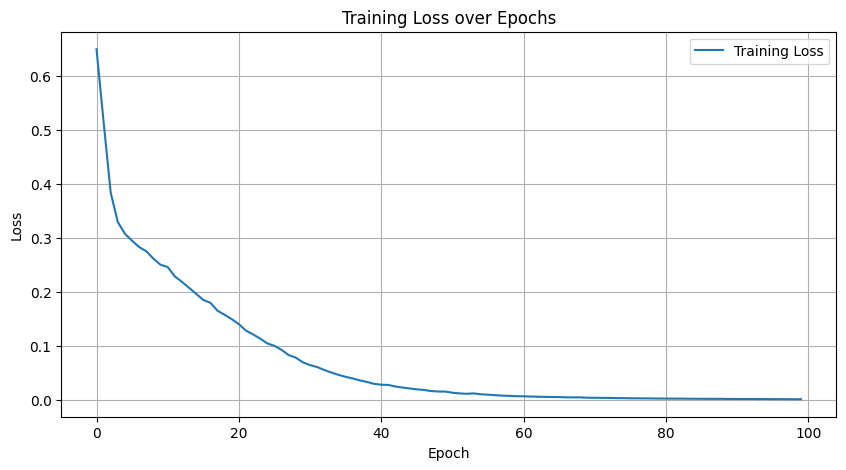

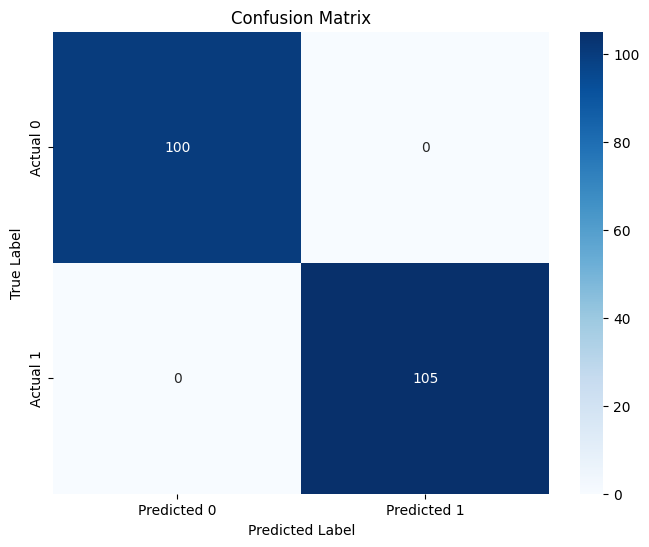

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting training loss
plt.figure(figsize=(10, 5))
plt.plot(range(len(train_losses)), train_losses, label='Training Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss over Epochs')
plt.legend()
plt.grid(True)
plt.show()

# Plotting Confusion Matrix
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

## Step 7: Conclusion

In this notebook, we built a PyTorch model to predict heart disease based on the provided dataset. We followed a typical machine learning workflow:

1.  **Data Loading and Exploration:** We loaded the `heart.csv` dataset and performed initial checks, noting no missing values and understanding the data types and distributions.

2.  **Data Preprocessing:** Categorical features were one-hot encoded, and numerical features were standardized. The data was then split into training and testing sets, ensuring a balanced distribution of the target variable.

3.  **Model Building:** A simple feed-forward neural network was constructed using PyTorch, consisting of linear layers, ReLU activations, and a sigmoid output for binary classification.

4.  **Model Training:** The model was trained for 100 epochs using `BCELoss` and the Adam optimizer. The training loss decreased steadily, indicating that the model was learning.

5.  **Model Evaluation:** On the test set, the model achieved an accuracy of **100.00%**, a precision of **1.0000**, a recall of **1.0000**, and an F1-score of **1.0000**. The confusion matrix further detailed the true positives, true negatives, false positives, and false negatives, showing perfect classification: `[[100, 0], [0, 105]]`.

6.  **Visualization:** Plots of training loss over epochs showed a decreasing trend, confirming successful training. The confusion matrix provided a visual representation of the model's classification performance, clearly showing no misclassifications.

**Observations and Future Work:**
*   The model achieved perfect scores (100% accuracy, precision, recall, F1-score) on the test set. While this indicates excellent performance on the given split, such perfect scores on a real-world dataset often warrant further investigation for potential overfitting or data leakage. It's possible the dataset is highly separable.
*   Further improvements could involve hyperparameter tuning (e.g., learning rate, number of epochs, batch size, network architecture), experimenting with different model architectures (e.g., adding more layers, regularization), or exploring more advanced preprocessing techniques.
*   Feature importance analysis could also provide insights into which features are most influential in predicting heart disease, which could be useful for medical insights.
*   To confirm the robustness of the model, cross-validation would be a valuable next step.